# 03 — Baselines and teachers (go / no-go)

Implements `notebooks/03_spec.md` (source of truth). Logic lives in `hebrew_token_tax.test3`,
`compressors` and `llm`; this notebook only configures, calls and shows. Guide: `03_README.md`.

## Run plan (change only the flags in cell 2, then *Run All*)

| Step | What | Flags (everything else as default) | Cost |
|---|---|---|---|
| 1 | Offline check (optional) | `PROVIDER_OVERRIDE = "fake"`, `RUN_LOCAL = RUN_TEACHERS = RUN_ANSWERS = RUN_JUDGE = True` | free |
| 2 | Smoke test (verifies the 4 model ids) | `RUN_SMOKE = True`, `CONFIRM_SPEND = True` | ~cents |
| 3 | Dry-run estimate (3 cases) | `RUN_LOCAL = RUN_TEACHERS = RUN_ANSWERS = RUN_JUDGE = True`, `CONFIRM_SPEND = False` | free (stops at the teacher estimate) |
| 4 | Dry run (3 cases) | as step 3, `CONFIRM_SPEND = True` | small |
| 5 | Full-run estimate (48 cases) | as step 3, `DRY_RUN_N = None` | free (local stage ~25 min CPU) |
| 6 | Full run | as step 5, `CONFIRM_SPEND = True` | paid |

After step 4 check the spend cell (15): spend per stage, failures, and output tokens used per role.
Paid stages print *calls to make / cached / estimated cost* and stop with `SpendBlocked`
unless `CONFIRM_SPEND = True`. If a stage stops midway (`BillingError`, `FatalCallError`,
`StageAborted`, `SpendBlocked`), read the message, fix the cause and run again: finished
calls come from the cache and are never paid twice.

### 1. Imports and prompts — loads the code and prints the 4 prompts verbatim from the spec. [FREE]

In [8]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display

from hebrew_token_tax.compressors import (
    LLMLINGUA2_LARGE,
    LLMLINGUA2_SMALL,
    LLMLingua2Compressor,
    NllbTranslator,
    RuleCompressor,
)
from hebrew_token_tax.llm import (
    AnthropicProvider,
    FakeProvider,
    GeminiProvider,
    LLMClient,
    OpenAIProvider,
    Price,
    guard_spend,
)
from hebrew_token_tax.test3 import (
    LANGUAGES,
    JsonStore,
    LocalCompressors,
    Role,
    answer_jobs,
    answer_requests,
    context,
    domain_drop_table,
    fake_reply,
    judge_jobs,
    judge_requests,
    load_cases,
    load_prompts,
    local_pending,
    method_grid,
    pending_teacher_jobs,
    plot_main_chart,
    plot_metric_bars,
    plot_savings_vs_accuracy,
    question_type_table,
    resolve_roles,
    results_table,
    run_answers,
    run_judge,
    run_local,
    run_teachers,
    score_rows,
    smoke_requests,
    summarize,
    teacher_length_table,
    teacher_request,
    token_ratio,
    write_summary_md,
)

SPEC_PATH = Path("03_spec.md")
PROMPTS = load_prompts(SPEC_PATH)
for name, prompt in PROMPTS.items():
    print(f"===== {name} =====\n{prompt}\n")

===== teacher_he =====
The text has {n_words} words. Shorten it to about {target_words} words
(keep rate {pct}%) by DELETING only. You may delete whole words, or one or more leading prefix letters
(ו ה ש ב ל כ מ, e.g. וה) from the start of a word. Do not add, reorder, rewrite or translate anything.
Never delete numbers, dates, names, negations or conditions.
Return only the shortened text.

===== teacher_en =====
The text has {n_words} words. Shorten it to about {target_words} words
(keep rate {pct}%) by DELETING whole words only. Do not add, reorder, rewrite or translate anything.
Never delete numbers, dates, names, negations or conditions.
Return only the shortened text.

===== teacher_feedback =====
Your previous output had {actual_words} words; the target is {target_words}. Delete more.

===== chatbot =====
You are a customer-service assistant. Answer the 3 questions using ONLY the
text below. Answer briefly, in {answer_language}. If the text does not contain
the answer, say so.
Re

### 2. Config — models, output limits, prices, budget caps and run flags. [FREE]

- Output limits include reasoning tokens and are only a ceiling (only used tokens are billed).
  Teachers 32k (one dry-run reply used 14k of 16k); chatbot 4k and judge 8k leave room for low/medium reasoning plus the short
  JSON. A reply that hits its limit is marked failed. The last cell shows the tokens actually
  used per role, so the limits can be tightened after the dry run.
- `DEFAULT_OUTPUT_TOKENS` only feeds the cost estimate until real usage is cached
  (teacher values set from the 3-case dry-run averages).
- `DRY_RUN_N = 3` = the first 3 cases of each language (same ids), reused from cache later.

In [9]:
TEACHER_SOL_MODEL = "gpt-6.1-sol"
TEACHER_OPUS_MODEL = "claude-opus-5-5"
CHATBOT_MODEL = "gpt-6.1-terra"
JUDGE_MODEL = "claude-sonnet-5-5"
TEACHER_MAX_OUTPUT_TOKENS = 32000
CHATBOT_MAX_OUTPUT_TOKENS = 4000
JUDGE_MAX_OUTPUT_TOKENS = 8000

ROLES = {
    "teacher_sol": Role("openai", TEACHER_SOL_MODEL, "high", TEACHER_MAX_OUTPUT_TOKENS),
    "teacher_opus": Role("anthropic", TEACHER_OPUS_MODEL, "high", TEACHER_MAX_OUTPUT_TOKENS),
    "chatbot": Role("openai", CHATBOT_MODEL, "low", CHATBOT_MAX_OUTPUT_TOKENS),
    "judge": Role("anthropic", JUDGE_MODEL, "medium", JUDGE_MAX_OUTPUT_TOKENS),
}
PRICES = {
    TEACHER_SOL_MODEL: Price(2.0, 10.0),
    TEACHER_OPUS_MODEL: Price(4.0, 20.0),
    CHATBOT_MODEL: Price(1.0, 5.0),
    JUDGE_MODEL: Price(2.0, 10.0),
}
BUDGET_CAPS = {"anthropic": 55.0, "openai": 20.0}
DEFAULT_OUTPUT_TOKENS = {
    "smoke": 50,
    "teacher_sol": 7000,
    "teacher_opus": 11000,
    "chatbot": 800,
    "judge": 1500,
}

KEEP_RATES = (0.7, 0.5)
DRY_RUN_N = None
PROVIDER_OVERRIDE = None
DEBUG_MODELS = {"gemini": "gemini-3.5-flash-lite", "fake": "fake"}
GEMINI_KEY_NAMES = ("GEMINI_API_KEY", "GEMINI_API_KEY_2")
GEMINI_REQUESTS_PER_MINUTE = 15

RUN_SMOKE = False
RUN_LOCAL = True
RUN_TEACHERS = True
RUN_ANSWERS = True
RUN_JUDGE = True
CONFIRM_SPEND = True

DATA_DIR = Path("..") / "data" / "03"
RESULTS_DIR = Path("..") / "results"
CACHE_DIR = Path("..") / "data" / "cache" / "03"
MODE = PROVIDER_OVERRIDE or "real"
STAGE_DIR = CACHE_DIR / MODE
SUFFIX = "" if MODE == "real" and DRY_RUN_N is None else f"_{MODE}_n{DRY_RUN_N or 'all'}"

if not RESULTS_DIR.is_dir():
    raise FileNotFoundError(f"{RESULTS_DIR} not found; run from the notebooks/ folder")
print(f"mode: {MODE}, cases per language: {DRY_RUN_N or 'all'}, result suffix: {SUFFIX!r}")
print(f"budget caps: {BUDGET_CAPS}, CONFIRM_SPEND = {CONFIRM_SPEND}")

mode: real, cases per language: all, result suffix: ''
budget caps: {'anthropic': 55.0, 'openai': 20.0}, CONFIRM_SPEND = True


### 3. Environment and client — loads `.env` only when a real provider needs keys (never in fake mode), checks the key names exist (values never printed), builds the client. [FREE]

In [10]:
KEY_NAMES = {
    "openai": ("OPENAI_API_KEY",),
    "anthropic": ("ANTHROPIC_API_KEY",),
    "gemini": GEMINI_KEY_NAMES,
    "fake": (),
}

roles = resolve_roles(ROLES, PROVIDER_OVERRIDE, DEBUG_MODELS)
providers_in_use = sorted({role.provider for role in roles.values()})
if any(KEY_NAMES[provider] for provider in providers_in_use):
    load_dotenv()
missing = [key for provider in providers_in_use for key in KEY_NAMES[provider] if not os.getenv(key)]
if missing:
    raise RuntimeError(f"Missing from .env: {', '.join(missing)}")

client = LLMClient(
    CACHE_DIR / "llm",
    providers={
        "openai": OpenAIProvider(),
        "anthropic": AnthropicProvider(),
        "gemini": GeminiProvider(GEMINI_KEY_NAMES, GEMINI_REQUESTS_PER_MINUTE),
        "fake": FakeProvider(fake_reply),
    },
    prices=PRICES,
    budget_caps=BUDGET_CAPS,
)
for name, role in roles.items():
    print(f"{name:13} {role.provider:10} {role.model:24} reasoning={role.reasoning:7} "
          f"max_output_tokens={role.max_output_tokens}")

teacher_sol   openai     gpt-6.1-sol              reasoning=high    max_output_tokens=32000
teacher_opus  anthropic  claude-opus-5-5          reasoning=high    max_output_tokens=32000
chatbot       openai     gpt-6.1-terra            reasoning=low     max_output_tokens=4000
judge         anthropic  claude-sonnet-5-5        reasoning=medium  max_output_tokens=8000


### 4. Cases — loads the cases (first `DRY_RUN_N` per language), builds the 23 method/rate/language combos, prints the Hebrew/English token ratio. [FREE]

In [11]:
cases = {language: load_cases(DATA_DIR, language, DRY_RUN_N) for language in LANGUAGES}
methods = method_grid(KEEP_RATES)
ratio = token_ratio(cases)

print(f"cases: {len(cases['he'])} he, {len(cases['en'])} en; {len(methods)} method/rate/language combos")
print(f"ids: {[case['id'] for case in cases['he']][:5]}{' ...' if len(cases['he']) > 5 else ''}")
print(
    f"Hebrew/English o200k ratio of originals: {ratio['overall']:.2f} overall "
    f"({ratio['he_tokens']} / {ratio['en_tokens']}), {ratio['mean_per_case']:.2f} mean per case"
)

cases: 48 he, 48 en; 23 method/rate/language combos
ids: ['ins_01', 'ins_02', 'ins_03', 'ins_04', 'ins_05'] ...
Hebrew/English o200k ratio of originals: 1.22 overall (38533 / 31667), 1.22 mean per case


### 5. Smoke test — one tiny "Reply with OK" call per model in use (`RUN_SMOKE`). [PAID]

In [12]:
if RUN_SMOKE:
    smoke = smoke_requests(roles)
    guard_spend(client, client.estimate(smoke, DEFAULT_OUTPUT_TOKENS), CONFIRM_SPEND, "smoke")
    for result in client.call_many(smoke, desc="smoke"):
        request = result.request
        print(
            f"{request.provider:10} {request.model:24} reply={result.text[:40]!r} "
            f"error={result.error or '-'} cost=${result.cost_usd:.5f} cached={result.cached}"
        )
else:
    print("smoke test skipped (RUN_SMOKE = False)")

smoke test skipped (RUN_SMOKE = False)


### 6. Local methods — rules, LLMLingua-2 large/small, NLLB, NLLB + LLMLingua-2 on CPU; models load only if something is pending (`RUN_LOCAL`). [FREE]

In [13]:
local = JsonStore(CACHE_DIR / "local.json")
pending = local_pending(cases, methods, local)
if RUN_LOCAL and pending:
    tools = LocalCompressors(
        rules={language: RuleCompressor(language, DATA_DIR) for language in LANGUAGES},
        llmlingua2_large=LLMLingua2Compressor(LLMLINGUA2_LARGE),
        llmlingua2_small=LLMLingua2Compressor(LLMLINGUA2_SMALL),
        translator=NllbTranslator(),
    )
    tools.warm_up(context(cases["he"][0]))
    print(f"compressed {run_local(cases, methods, tools, local)} texts")
else:
    print(f"local stage skipped (RUN_LOCAL = {RUN_LOCAL}, pending = {pending})")
print(f"stored local compressions: {len(local.data)}")

local stage skipped (RUN_LOCAL = True, pending = 0)
stored local compressions: 720


### 7. Teachers — two LLMs shorten each text by deletion only, to an exact word target; invalid output is retried, output > 0.10 above the keep rate is retried with length feedback (max 2 retries); the closest valid output is kept (`RUN_TEACHERS`). [PAID]

In [14]:
teachers = JsonStore(STAGE_DIR / "teachers.json")
if RUN_TEACHERS:
    jobs = pending_teacher_jobs(cases, methods, teachers, PROMPTS)
    first_attempts = [teacher_request(roles, PROMPTS, case, method, 0) for case, method in jobs]
    guard_spend(client, client.estimate(first_attempts, DEFAULT_OUTPUT_TOKENS), CONFIRM_SPEND, "teachers")
    print(f"teacher failures this run: {run_teachers(client, roles, PROMPTS, jobs, teachers)}")
failed = sum(record["teacher_failed"] for record in teachers.data.values())
length_misses = sum(record.get("length_miss", False) for record in teachers.data.values())
print(f"stored teacher compressions: {len(teachers.data)}, failed: {failed}, "
      f"length misses (closest valid kept): {length_misses}")

teachers: 360 calls to make, 0 cached, est. $48.528
  anthropic: 180 to make, 0 cached, est. $35.236, spent so far $4.86 of $55.00 cap
  openai: 180 to make, 0 cached, est. $13.292, spent so far $2.75 of $20.00 cap


teachers (attempt 1):   0%|          | 0/360 [00:00<?, ?it/s]

teachers (attempt 2):   0%|          | 0/10 [00:00<?, ?it/s]

teachers (attempt 3):   0%|          | 0/3 [00:00<?, ?it/s]

teacher failures this run: 2
stored teacher compressions: 384, failed: 2, length misses (closest valid kept): 0


### 8. Chatbot answers — answers the 3 questions from each text as JSON; invalid JSON is retried once, then counted as 3 incorrect (`RUN_ANSWERS`). [PAID]

In [15]:
compressions = JsonStore.combined(local, teachers)
answers = JsonStore(STAGE_DIR / "answers.json")
if RUN_ANSWERS:
    jobs = answer_jobs(cases, methods, compressions, answers, PROMPTS)
    requests = answer_requests(roles, PROMPTS, jobs, compressions)
    guard_spend(client, client.estimate(requests, DEFAULT_OUTPUT_TOKENS), CONFIRM_SPEND, "answers")
    print(f"answer JSON failures this run: {run_answers(client, roles, PROMPTS, jobs, compressions, answers)}")
json_failed = sum(record["json_failed"] for record in answers.data.values())
print(f"stored answer sets: {len(answers.data)}, JSON failures: {json_failed}")

answers: 1033 calls to make, 0 cached, est. $0.814
  openai: 1033 to make, 0 cached, est. $0.814, spent so far $15.35 of $20.00 cap


answers:   0%|          | 0/1033 [00:00<?, ?it/s]

answer JSON failures this run: 0
stored answer sets: 1104, JSON failures: 0


### 9. Judge — one blind call per answer set grades the 3 answers against the correct answers; invalid JSON counts as incorrect A changed judge prompt re-judges every row (answers are reused) (`RUN_JUDGE`). [PAID]

In [16]:
judgements = JsonStore(STAGE_DIR / "judgements.json")
if RUN_JUDGE:
    jobs = judge_jobs(cases, methods, answers, judgements, PROMPTS)
    requests = judge_requests(roles, PROMPTS, jobs, answers)
    guard_spend(client, client.estimate(requests, DEFAULT_OUTPUT_TOKENS), CONFIRM_SPEND, "judge")
    print(f"judge JSON failures this run: {run_judge(client, roles, PROMPTS, jobs, answers, judgements)}")
json_failed = sum(record["json_failed"] for record in judgements.data.values())
print(f"stored judgements: {len(judgements.data)}, JSON failures: {json_failed}")

judge: 807 calls to make, 0 cached, est. $1.321
  anthropic: 807 to make, 0 cached, est. $1.321, spent so far $38.52 of $55.00 cap


judge:   0%|          | 0/807 [00:00<?, ?it/s]

judge JSON failures this run: 0
stored judgements: 1104, JSON failures: 0


### 10. Results: main chart — tokens saved vs. answers correct, one panel per language; each method is one line from keep rate 0.7 to 0.5; saves `results/03_main_chart*.png`, `03_results*.csv` and `03_summary*.csv`. No verdict, no thresholds. [FREE]

Note: facts_kept for translation methods checks digits only and does not detect currency errors (e.g. ש״ח -> dollars).

1104 case rows, 23 summary rows saved to ..\results


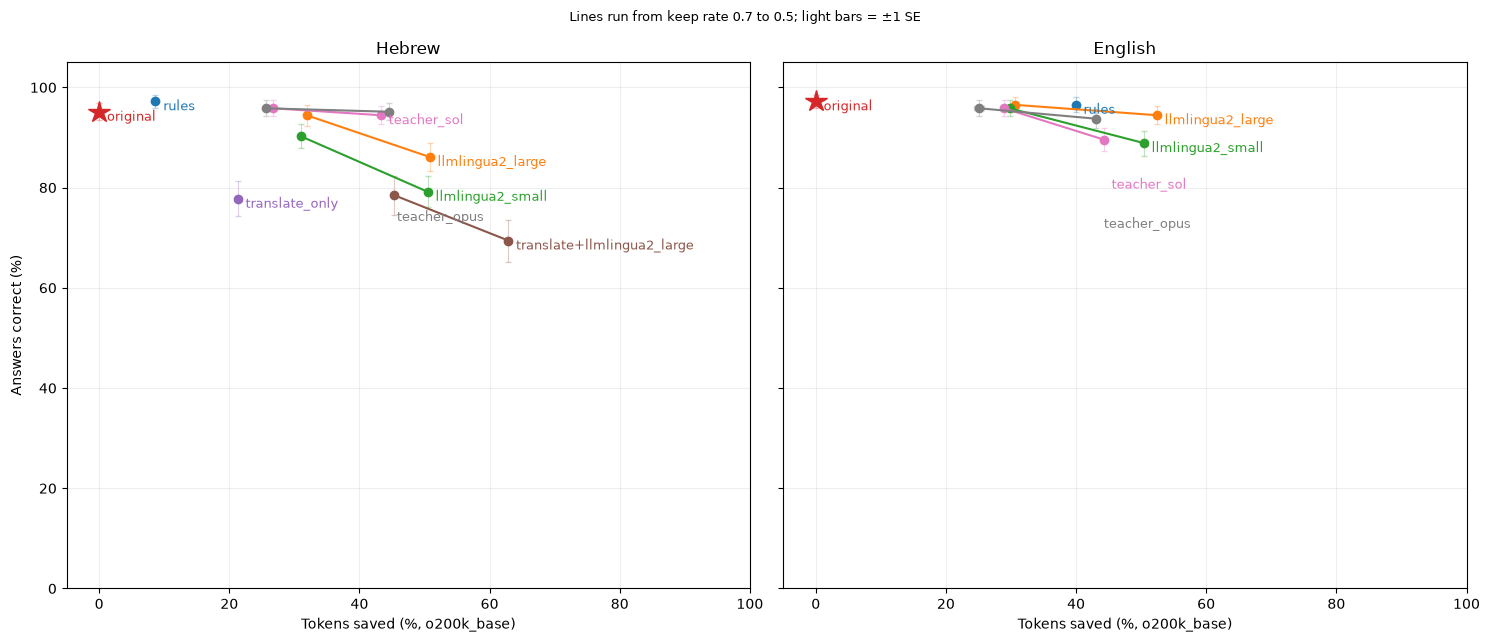

In [17]:
rows = score_rows(cases, methods, compressions, answers, judgements)
summary = summarize(rows)
rows.to_csv(RESULTS_DIR / f"03_results{SUFFIX}.csv", index=False)
summary.to_csv(RESULTS_DIR / f"03_summary{SUFFIX}.csv", index=False)
print(f"{len(rows)} case rows, {len(summary)} summary rows saved to {RESULTS_DIR}")

main_chart = ("Main chart: tokens saved vs. answers correct", f"03_main_chart{SUFFIX}.png")
plot_main_chart(summary, RESULTS_DIR / main_chart[1])
plt.show()

### 11. Results (a): summary table — one row per language × method × keep rate; plus requested vs. actual keep rate and attempts per teacher row (`03_teacher_length*.csv`). [FREE]

In [18]:
table_a = results_table(summary)
display(table_a.round(1))

table_teacher = teacher_length_table(rows)
table_teacher.to_csv(RESULTS_DIR / f"03_teacher_length{SUFFIX}.csv", index=False)
display(table_teacher.round(2))

,language,method,rate,cases,savings %,tokens saved per case,accuracy %,accuracy drop vs original,facts kept %,latency ms,teacher failures,JSON failures
0,he,original,NaN,48,0.0,0.0,95.1,0.0,100.0,0.0,0,0
1,he,rules,NaN,48,8.7,73.1,97.2,-2.1,91.4,2.7,0,0
2,he,llmlingua2_large,0.7,48,31.9,254.5,94.4,0.7,85.7,3303.1,0,0
3,he,llmlingua2_large,0.5,48,50.8,407.1,86.1,9.0,74.1,4690.1,0,0
4,he,llmlingua2_small,0.7,48,30.9,247.8,90.3,4.9,82.3,1229.0,0,0
5,he,llmlingua2_small,0.5,48,50.5,405.1,79.2,16.0,73.1,1206.2,0,0
6,he,translate_only,NaN,48,21.3,170.5,77.8,17.4,92.0,17008.1,0,0
7,he,translate+llmlingua2_large,0.7,48,45.4,364.4,78.5,16.7,92.0,21131.8,0,0
8,he,translate+llmlingua2_large,0.5,48,62.9,505.1,69.4,25.7,91.7,19924.7,0,0
9,he,teacher_sol,0.7,48,26.7,215.9,95.8,-0.7,98.7,NaN,0,0


,language,case_id,method,requested_keep,actual_keep,attempts,length_miss,teacher_failed
0,he,ins_01,teacher_sol,0.7,0.70,1,0,0
1,he,ins_02,teacher_sol,0.7,0.71,1,0,0
2,he,ins_03,teacher_sol,0.7,0.70,1,0,0
3,he,ins_04,teacher_sol,0.7,0.71,1,0,0
4,he,ins_05,teacher_sol,0.7,0.70,1,0,0
...,...,...,...,...,...,...,...,...
379,en,util_04,teacher_opus,0.5,0.58,1,0,0
380,en,util_05,teacher_opus,0.5,0.52,1,0,0
381,en,util_06,teacher_opus,0.5,0.52,1,0,0
382,en,util_07,teacher_opus,0.5,0.54,1,0,0


### 12. Results (b): accuracy per question type — Q1 numbers/dates, Q2 negations/conditions, Q3 from history; saves `03_question_types*.csv`. [FREE]

In [19]:
table_b = question_type_table(summary)
table_b.to_csv(RESULTS_DIR / f"03_question_types{SUFFIX}.csv", index=False)
display(table_b.round(1))

,language,method,rate,Q1 numbers/dates,Q2 negations/conditions,Q3 from history
0,he,original,NaN,97.9,87.5,100.0
1,he,rules,NaN,100.0,91.7,100.0
2,he,llmlingua2_large,0.7,97.9,85.4,100.0
3,he,llmlingua2_large,0.5,97.9,68.8,91.7
4,he,llmlingua2_small,0.7,95.8,75.0,100.0
5,he,llmlingua2_small,0.5,87.5,54.2,95.8
6,he,translate_only,NaN,64.6,85.4,83.3
7,he,translate+llmlingua2_large,0.7,72.9,83.3,79.2
8,he,translate+llmlingua2_large,0.5,70.8,66.7,70.8
9,he,teacher_sol,0.7,100.0,91.7,95.8


### 13. Results (c): more charts — savings vs. accuracy (±1 SE, original marked), accuracy bars, facts-kept bars; saves 3 PNGs. [FREE]

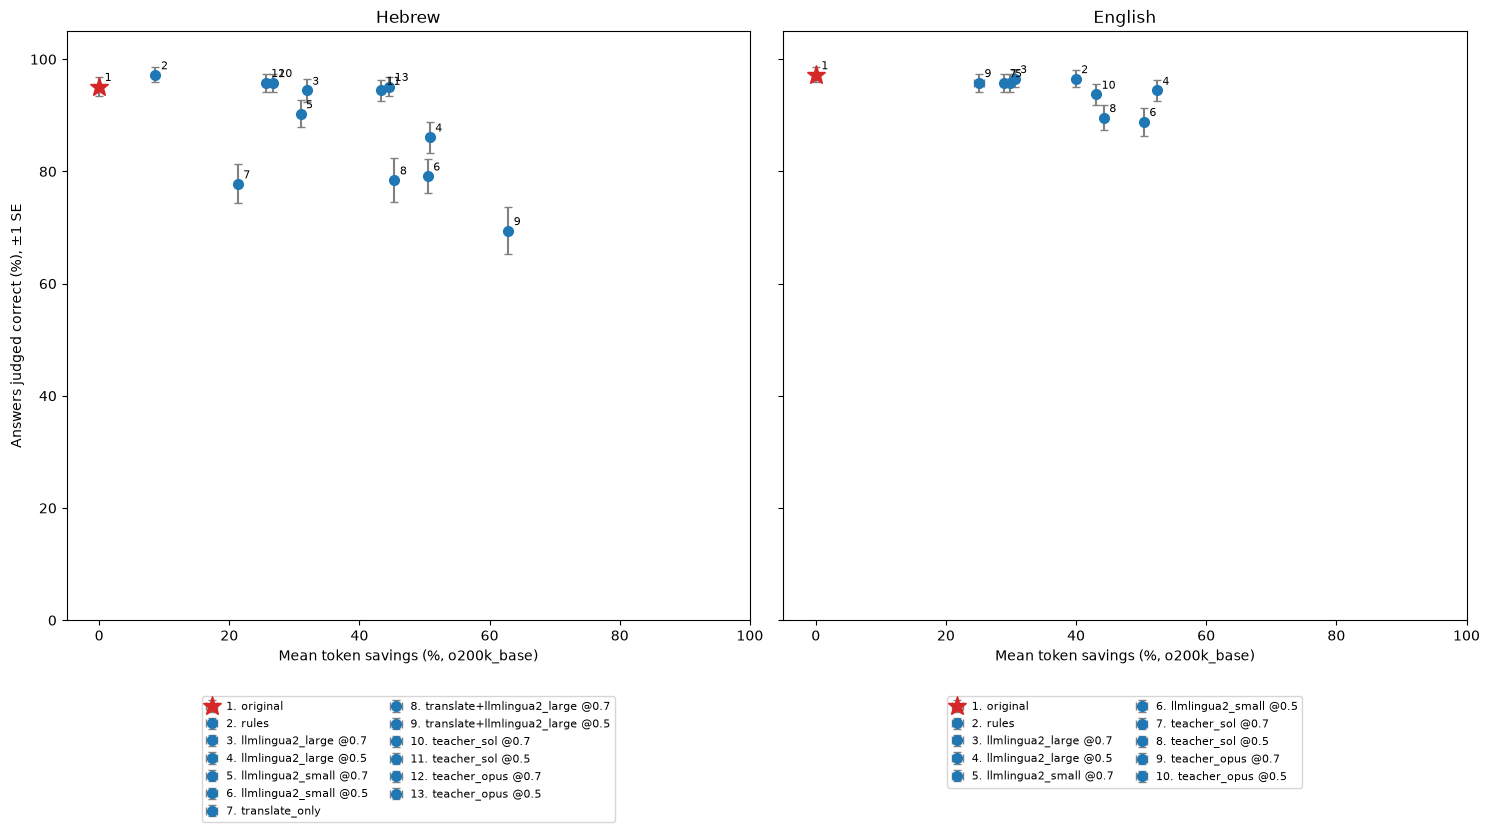

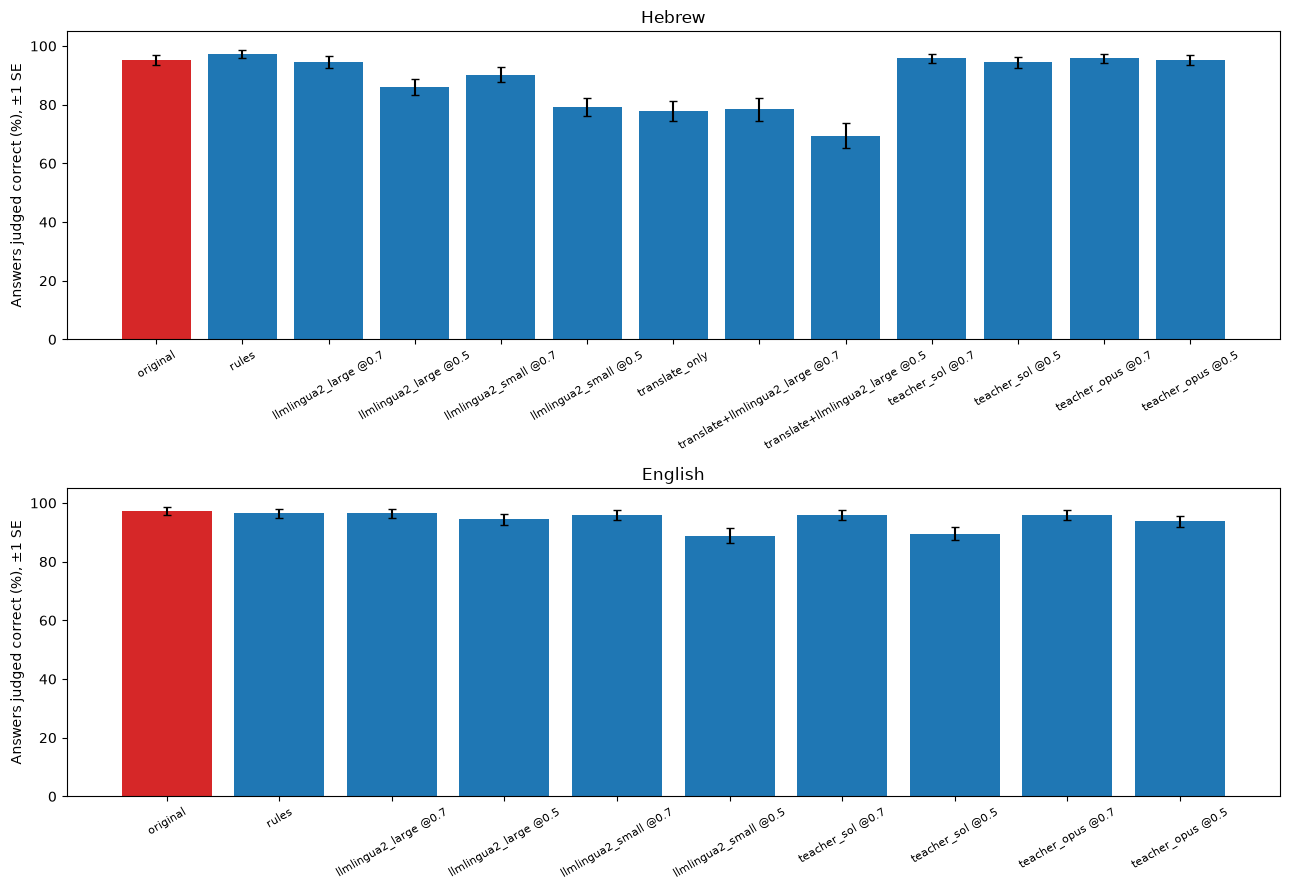

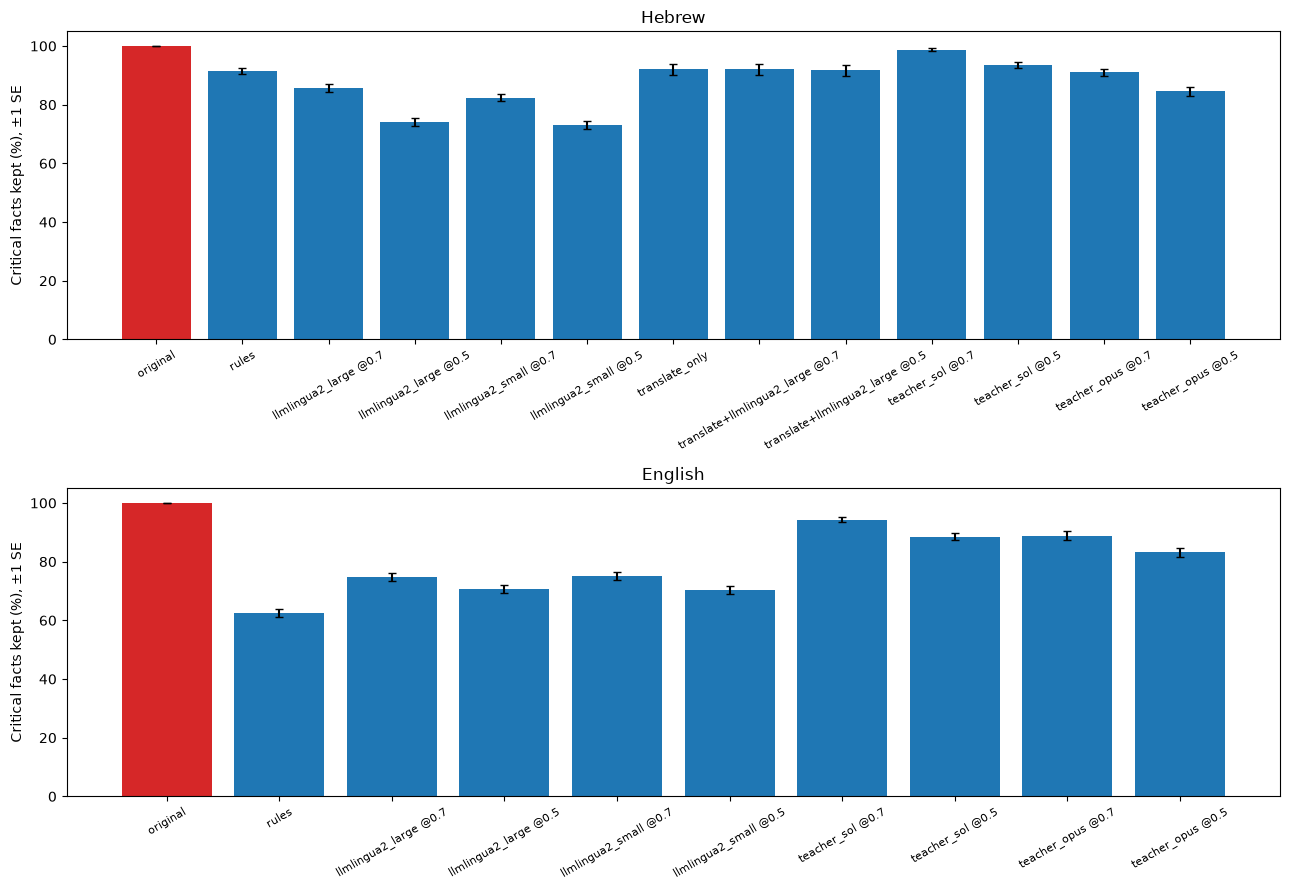

In [20]:
chart_files = {
    "Savings vs. accuracy": f"03_savings_vs_accuracy{SUFFIX}.png",
    "Accuracy per method": f"03_accuracy_bars{SUFFIX}.png",
    "Facts kept per method": f"03_facts_kept_bars{SUFFIX}.png",
}
plot_savings_vs_accuracy(summary, RESULTS_DIR / chart_files["Savings vs. accuracy"])
plot_metric_bars(summary, "accuracy_pct", "accuracy_se", "Answers judged correct (%), ±1 SE",
                 RESULTS_DIR / chart_files["Accuracy per method"])
plot_metric_bars(summary, "facts_kept_pct", "facts_kept_se", "Critical facts kept (%), ±1 SE",
                 RESULTS_DIR / chart_files["Facts kept per method"])
plt.show()

### 14. Results (d): accuracy drop vs. original per domain — llmlingua2_large and both teachers; saves `03_domain_drop*.csv`. [FREE]

In [21]:
table_d = domain_drop_table(rows)
table_d.to_csv(RESULTS_DIR / f"03_domain_drop{SUFFIX}.csv", index=False)
display(table_d.round(1))

domain,language,method,rate,banking,health_fund,insurance,online_shopping,telecom,utilities
0,en,llmlingua2_large,0.5,4.2,8.3,0.0,4.2,4.2,-4.2
1,en,llmlingua2_large,0.7,4.2,0.0,0.0,4.2,0.0,-4.2
2,en,teacher_opus,0.5,4.2,0.0,4.2,4.2,4.2,4.2
3,en,teacher_opus,0.7,4.2,0.0,4.2,4.2,0.0,-4.2
4,en,teacher_sol,0.5,12.5,4.2,8.3,4.2,12.5,4.2
5,en,teacher_sol,0.7,0.0,0.0,4.2,4.2,0.0,0.0
6,he,llmlingua2_large,0.5,25.0,8.3,4.2,-4.2,16.7,4.2
7,he,llmlingua2_large,0.7,0.0,4.2,0.0,-4.2,4.2,0.0
8,he,teacher_opus,0.5,0.0,0.0,4.2,-4.2,4.2,-4.2
9,he,teacher_opus,0.7,0.0,0.0,0.0,-4.2,0.0,0.0


### 15. Results (e): spend — per stage and provider: calls, new and cached this session, tokens in/out, $; plus output tokens used per role vs. its limit; saves `03_spend*.csv`. [FREE]

In [22]:
table_e = pd.DataFrame(client.spend_by_stage())
table_e.to_csv(RESULTS_DIR / f"03_spend{SUFFIX}.csv", index=False)
display(table_e)

all_time = client.all_time_spend()
for provider, cost in sorted(all_time.items()):
    cap = BUDGET_CAPS.get(provider)
    print(f"{provider}: ${cost:.4f} all time" + (f" of ${cap:.2f} cap" if cap else ""))
print(f"total: ${sum(all_time.values()):.4f} (this session ${sum(client.ledger.cost.values()):.4f})")
display(pd.DataFrame(client.usage_by_role()))

,stage,provider,calls (all time),new this session,cached this session,tokens in,tokens out,cost $
0,chatbot,openai,1126,1033,0,673104,54613,0.9462
1,judge,anthropic,896,807,0,300478,112011,1.7211
2,smoke,anthropic,2,0,0,28,8,0.0002
3,smoke,openai,2,0,0,18,10,0.0001
4,teacher_opus,anthropic,216,192,0,288168,1861052,38.3737
5,teacher_sol,openai,217,181,0,179451,1490856,15.2675


anthropic: $40.0950 all time of $55.00 cap
openai: $16.2137 all time of $20.00 cap
total: $56.3087 (this session $48.6943)


,role,model,calls,cost_usd,mean_output_tokens,max_output_tokens,output_limit,cut_off
0,chatbot,gpt-6.1-terra,1126,0.9462,49,290,4000,0
1,judge,claude-sonnet-5-5,896,1.7211,125,445,8000,0
2,smoke,claude-opus-5-5,1,0.0001,4,4,16000,0
3,smoke,claude-sonnet-5-5,1,0.0001,4,4,8000,0
4,smoke,gpt-6.1-sol,1,0.0001,5,5,16000,0
5,smoke,gpt-6.1-terra,1,0.0000,5,5,4000,0
6,teacher_opus,claude-opus-5-5,216,38.3737,8616,23143,16000,0
7,teacher_sol,gpt-6.1-sol,217,15.2675,6870,18161,32000,0


### 16. Results (f): `results/03_summary*.md` — main chart first, then the token ratio, all tables (a, teacher length, b, d, e) and the other 3 charts. [FREE]

In [23]:
summary_md = RESULTS_DIR / f"03_summary{SUFFIX}.md"
write_summary_md(
    summary_md,
    ratio,
    {language: len(cases[language]) for language in LANGUAGES},
    tables=[
        ("(a) Summary", table_a),
        ("Teacher length: requested vs. actual keep rate (words)", table_teacher),
        ("(b) Accuracy per question type (%)", table_b),
        ("(d) Accuracy drop vs. original per domain (points)", table_d),
        ("(e) Spend per stage and provider ($)", table_e),
    ],
    charts=list(chart_files.items()),
    main_chart=main_chart,
)
print(f"-> {summary_md}")

-> ..\results\03_summary.md
